In [ ]:
!nvidia-smi

Wed May 28 03:08:29 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.133.20             Driver Version: 570.133.20     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   29C    P0             42W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLO11 via Ultralytics

In [ ]:
%pip install "ultralytics<=8.3.40" supervision roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
Setup complete ✅ (12 CPUs, 83.5 GB RAM, 42.1/94.3 GB disk)


In [ ]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="YKjKJq9jwCbXAUxun5s3")
project = rf.workspace("work-4u6cx").project("yolv5-detection")
version = project.version(3)
dataset = version.download("yolov11")


/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to YOLV5-Detection-3 in yolov11:: 100%|██████████| 6858/6858 [00:00<00:00, 7744.24it/s]


## Custom Training

In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolo11s.pt data={dataset.location}/data.yaml epochs=300 imgsz=640 plots=True

/content
100% 18.4M/18.4M [00:00<00:00, 148MB/s] 
New https://pypi.org/project/ultralytics/8.3.146 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
engine/trainer: task=detect, mode=train, model=yolo11s.pt, data=/content/datasets/YOLV5-Detection-3/data.yaml, epochs=300, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnost

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

In [ ]:
!ls {HOME}/runs/detect/train/

args.yaml					   R_curve.png		 val_batch0_labels.jpg
confusion_matrix_normalized.png			   results.csv		 val_batch0_pred.jpg
confusion_matrix.png				   results.png		 val_batch1_labels.jpg
events.out.tfevents.1748401746.7d2feee65a0e.367.0  train_batch0.jpg	 val_batch1_pred.jpg
F1_curve.png					   train_batch1.jpg	 val_batch2_labels.jpg
labels_correlogram.jpg				   train_batch2.jpg	 val_batch2_pred.jpg
labels.jpg					   train_batch54520.jpg  weights
P_curve.png					   train_batch54521.jpg
PR_curve.png					   train_batch54522.jpg


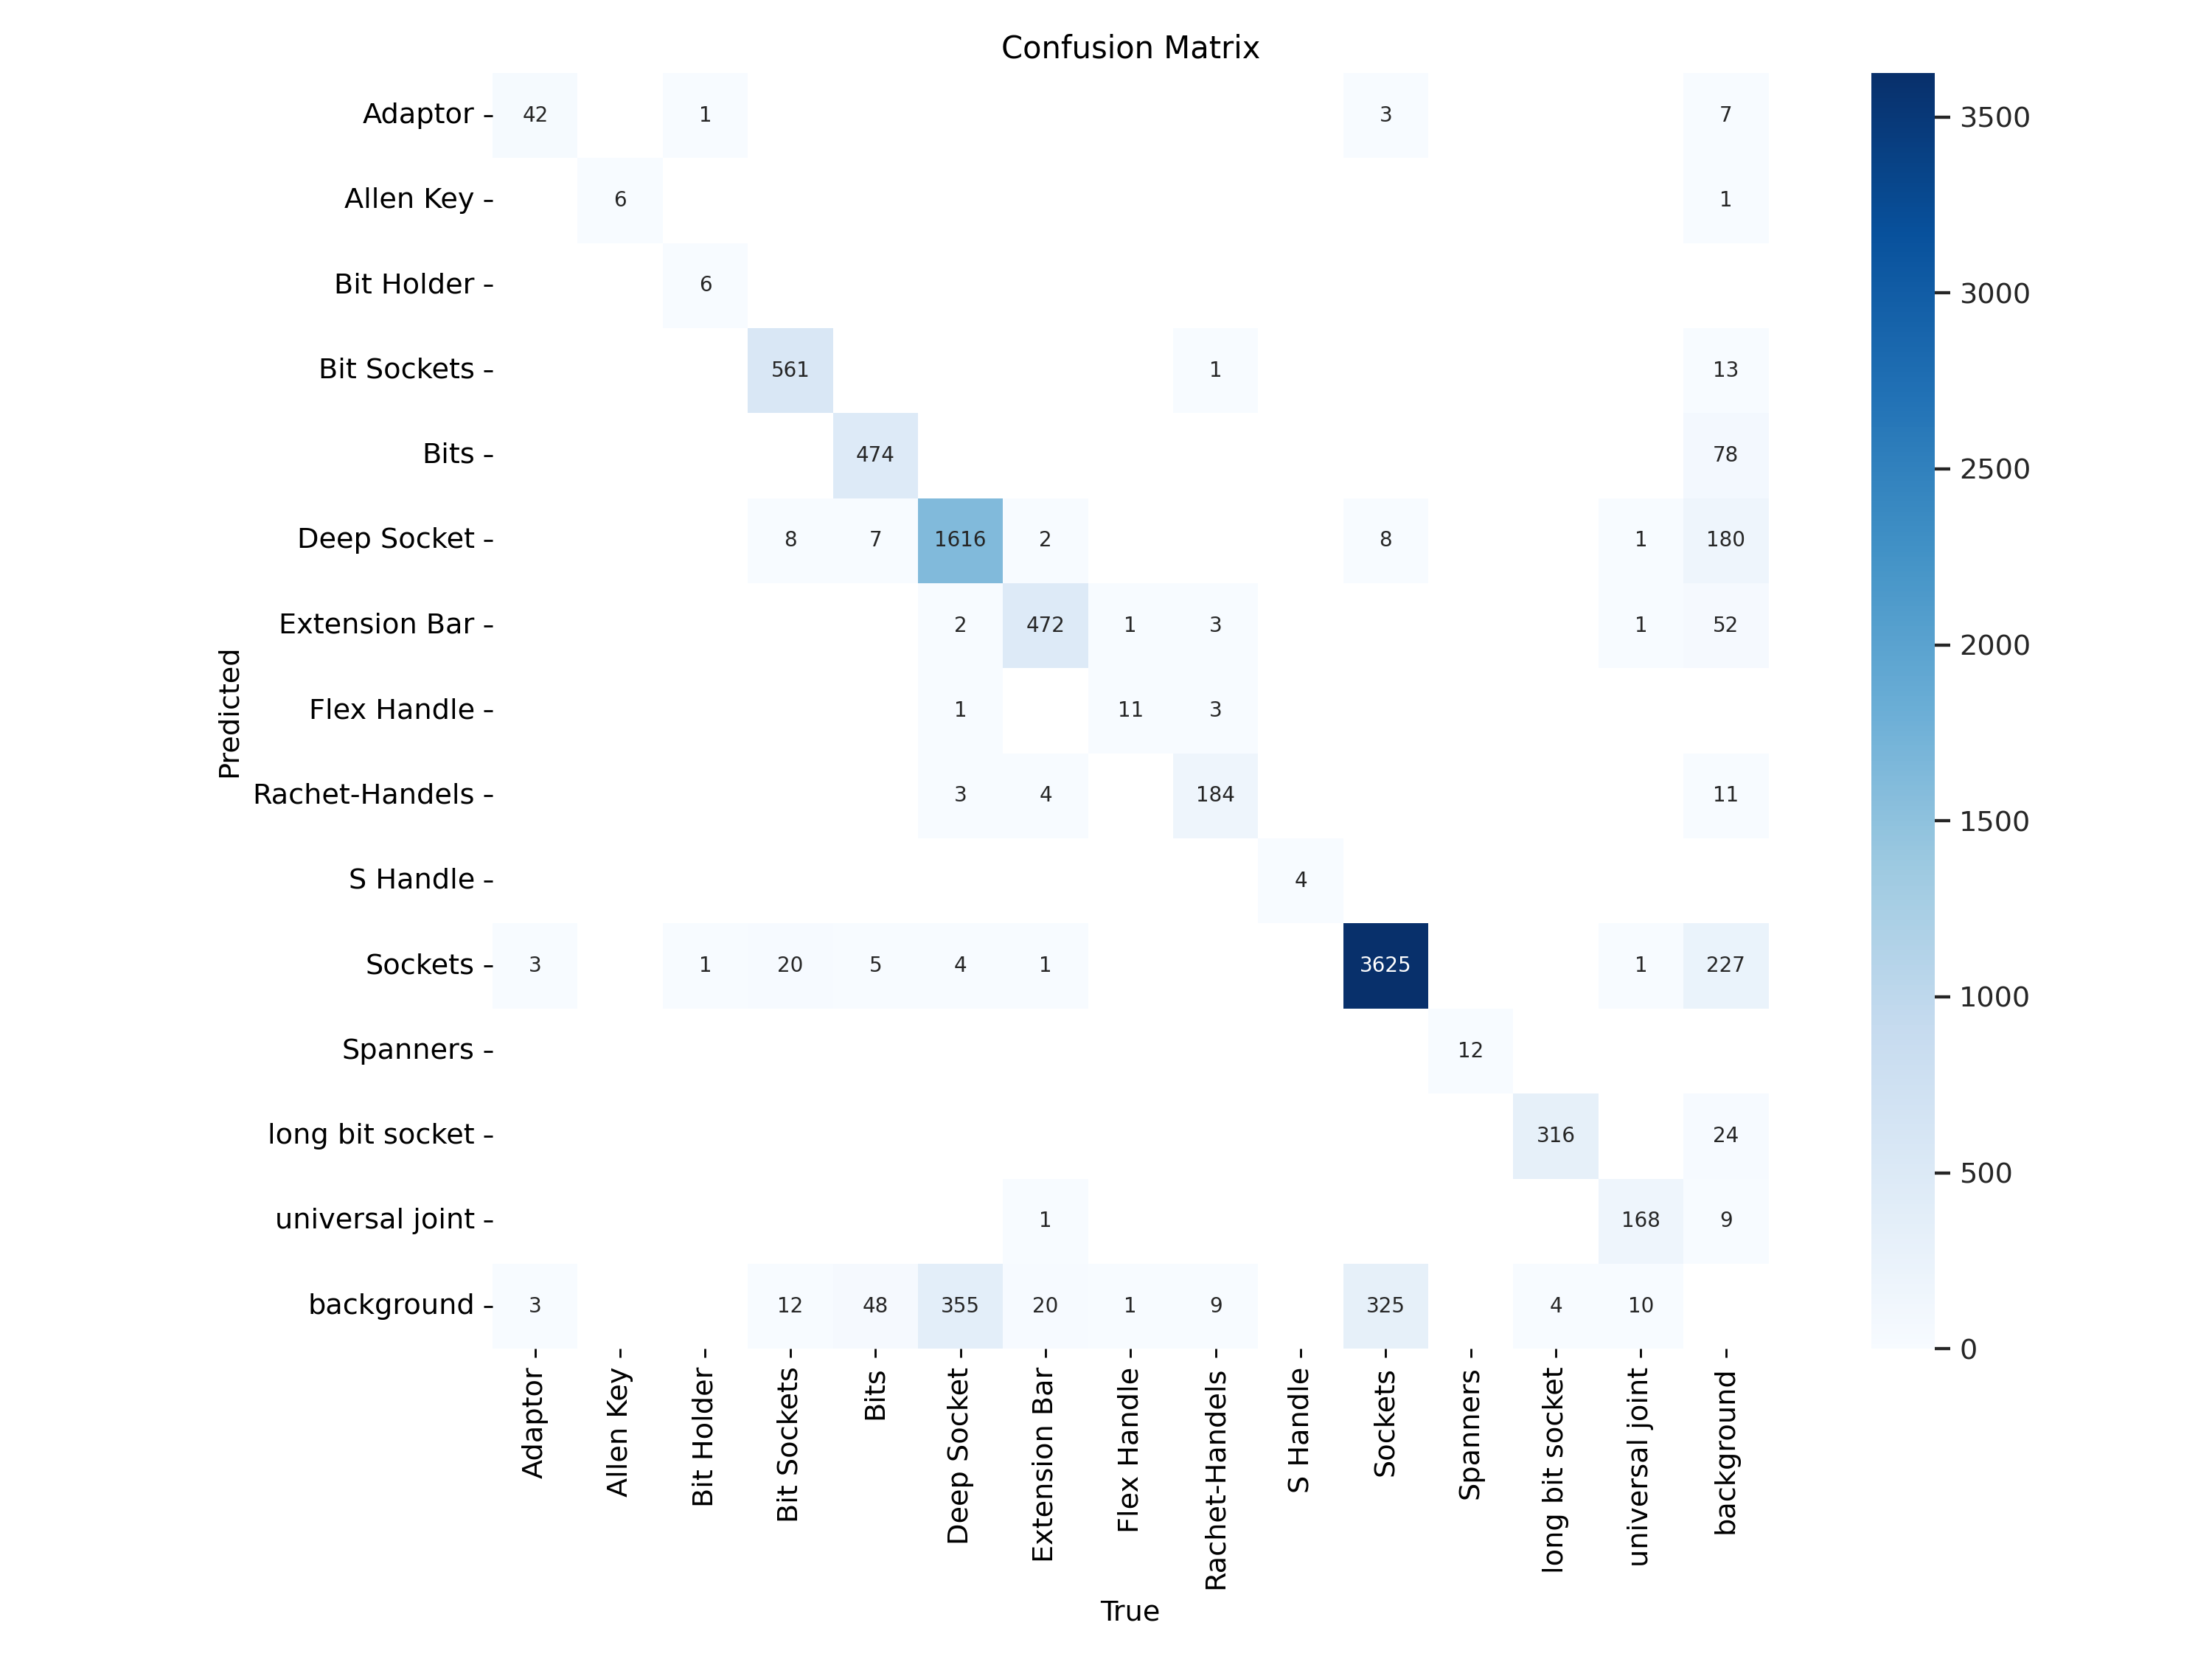

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/confusion_matrix.png', width=600)

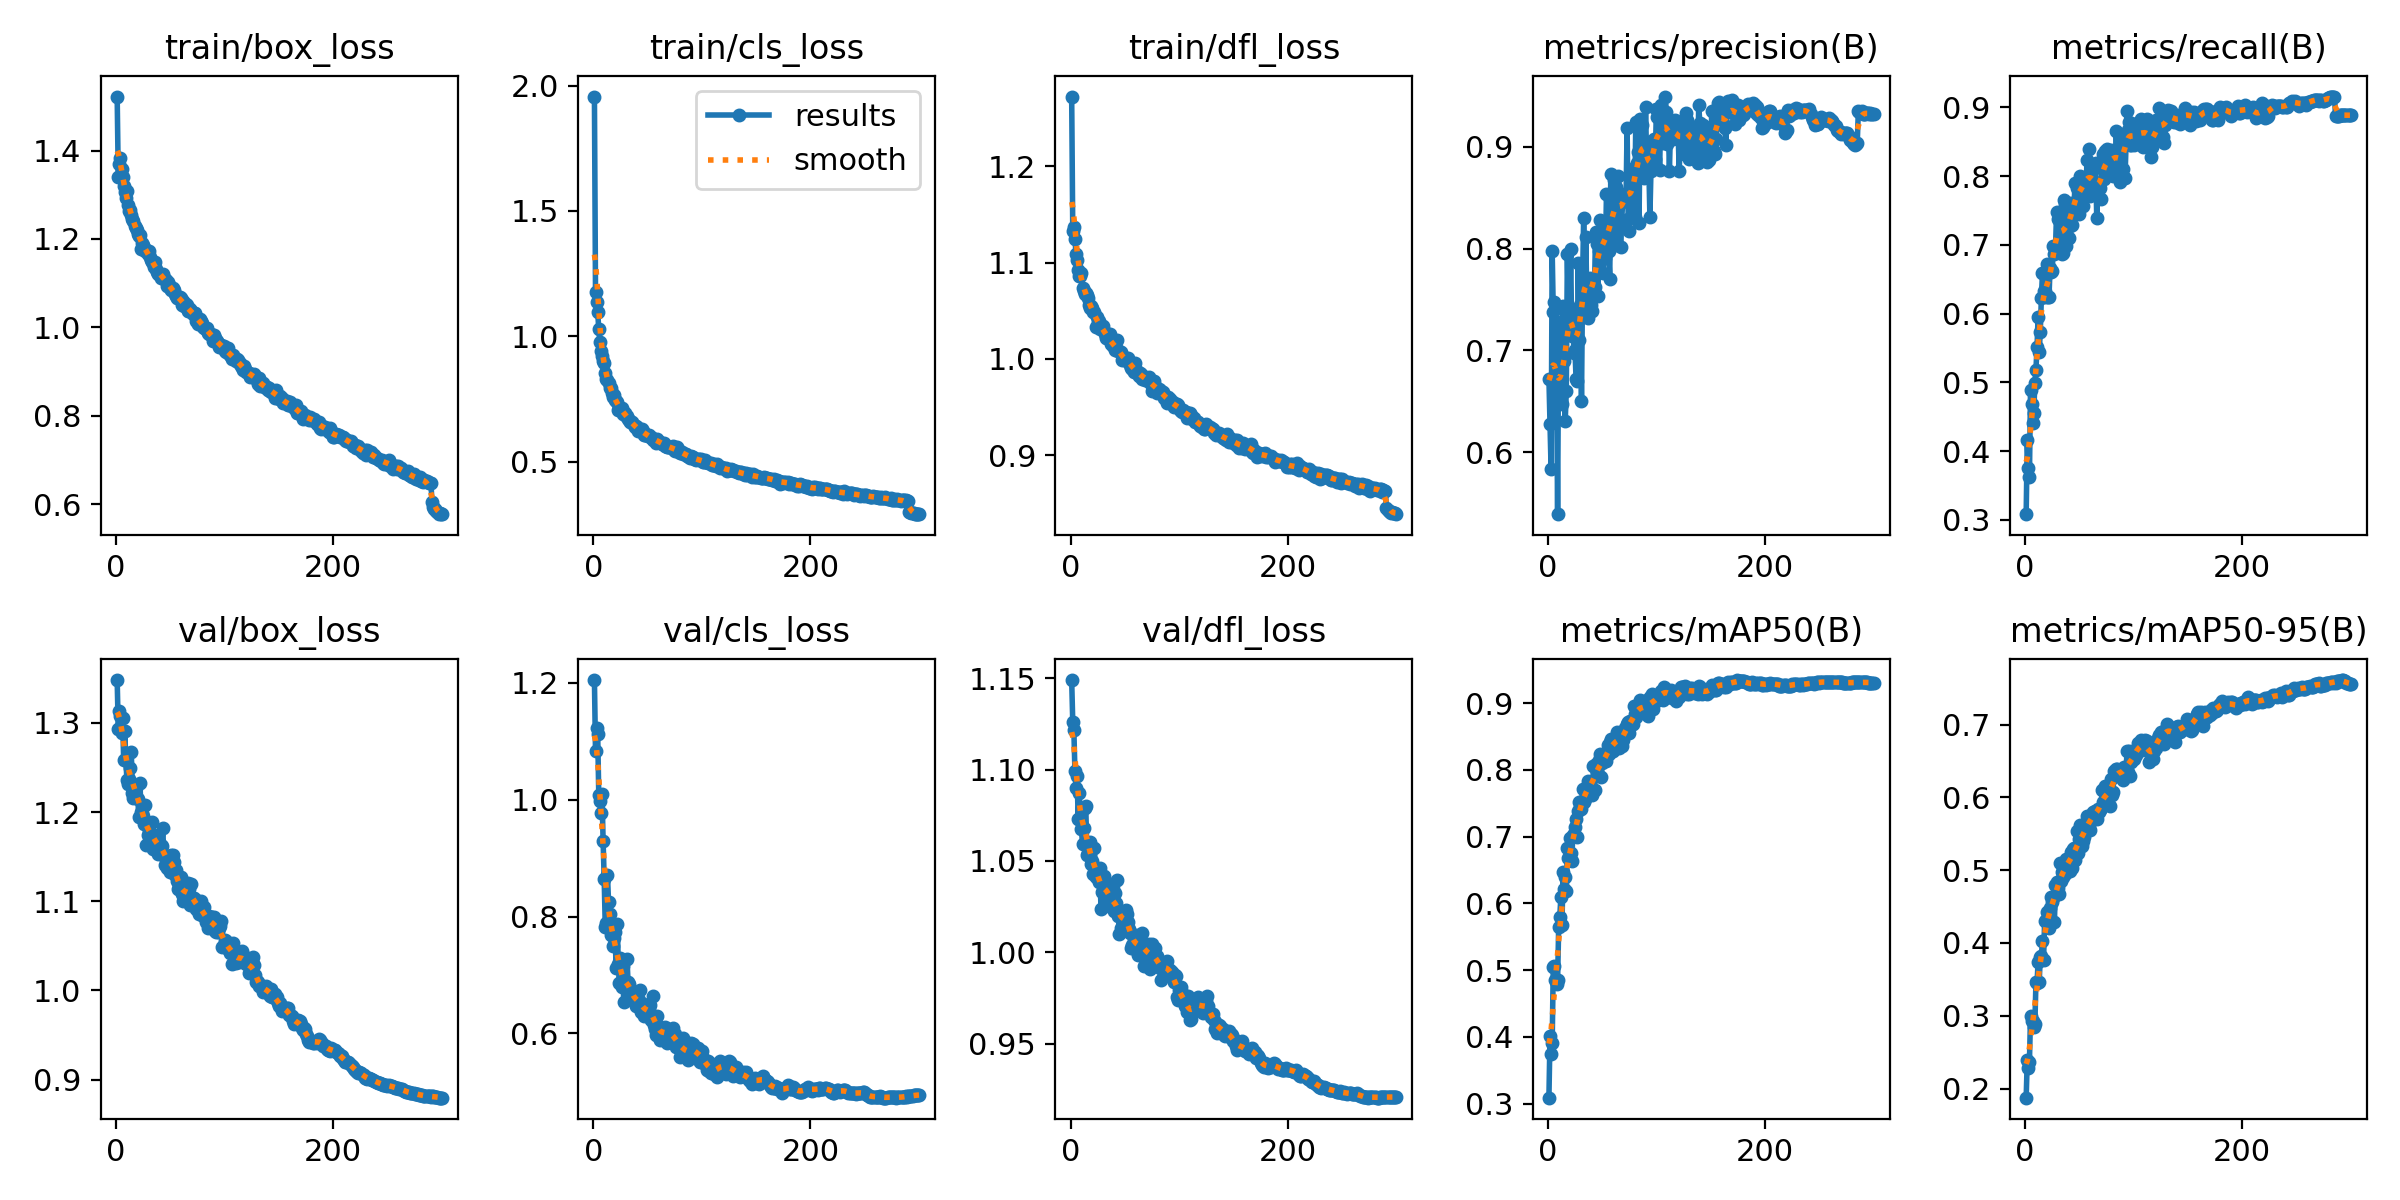

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/results.png', width=600)

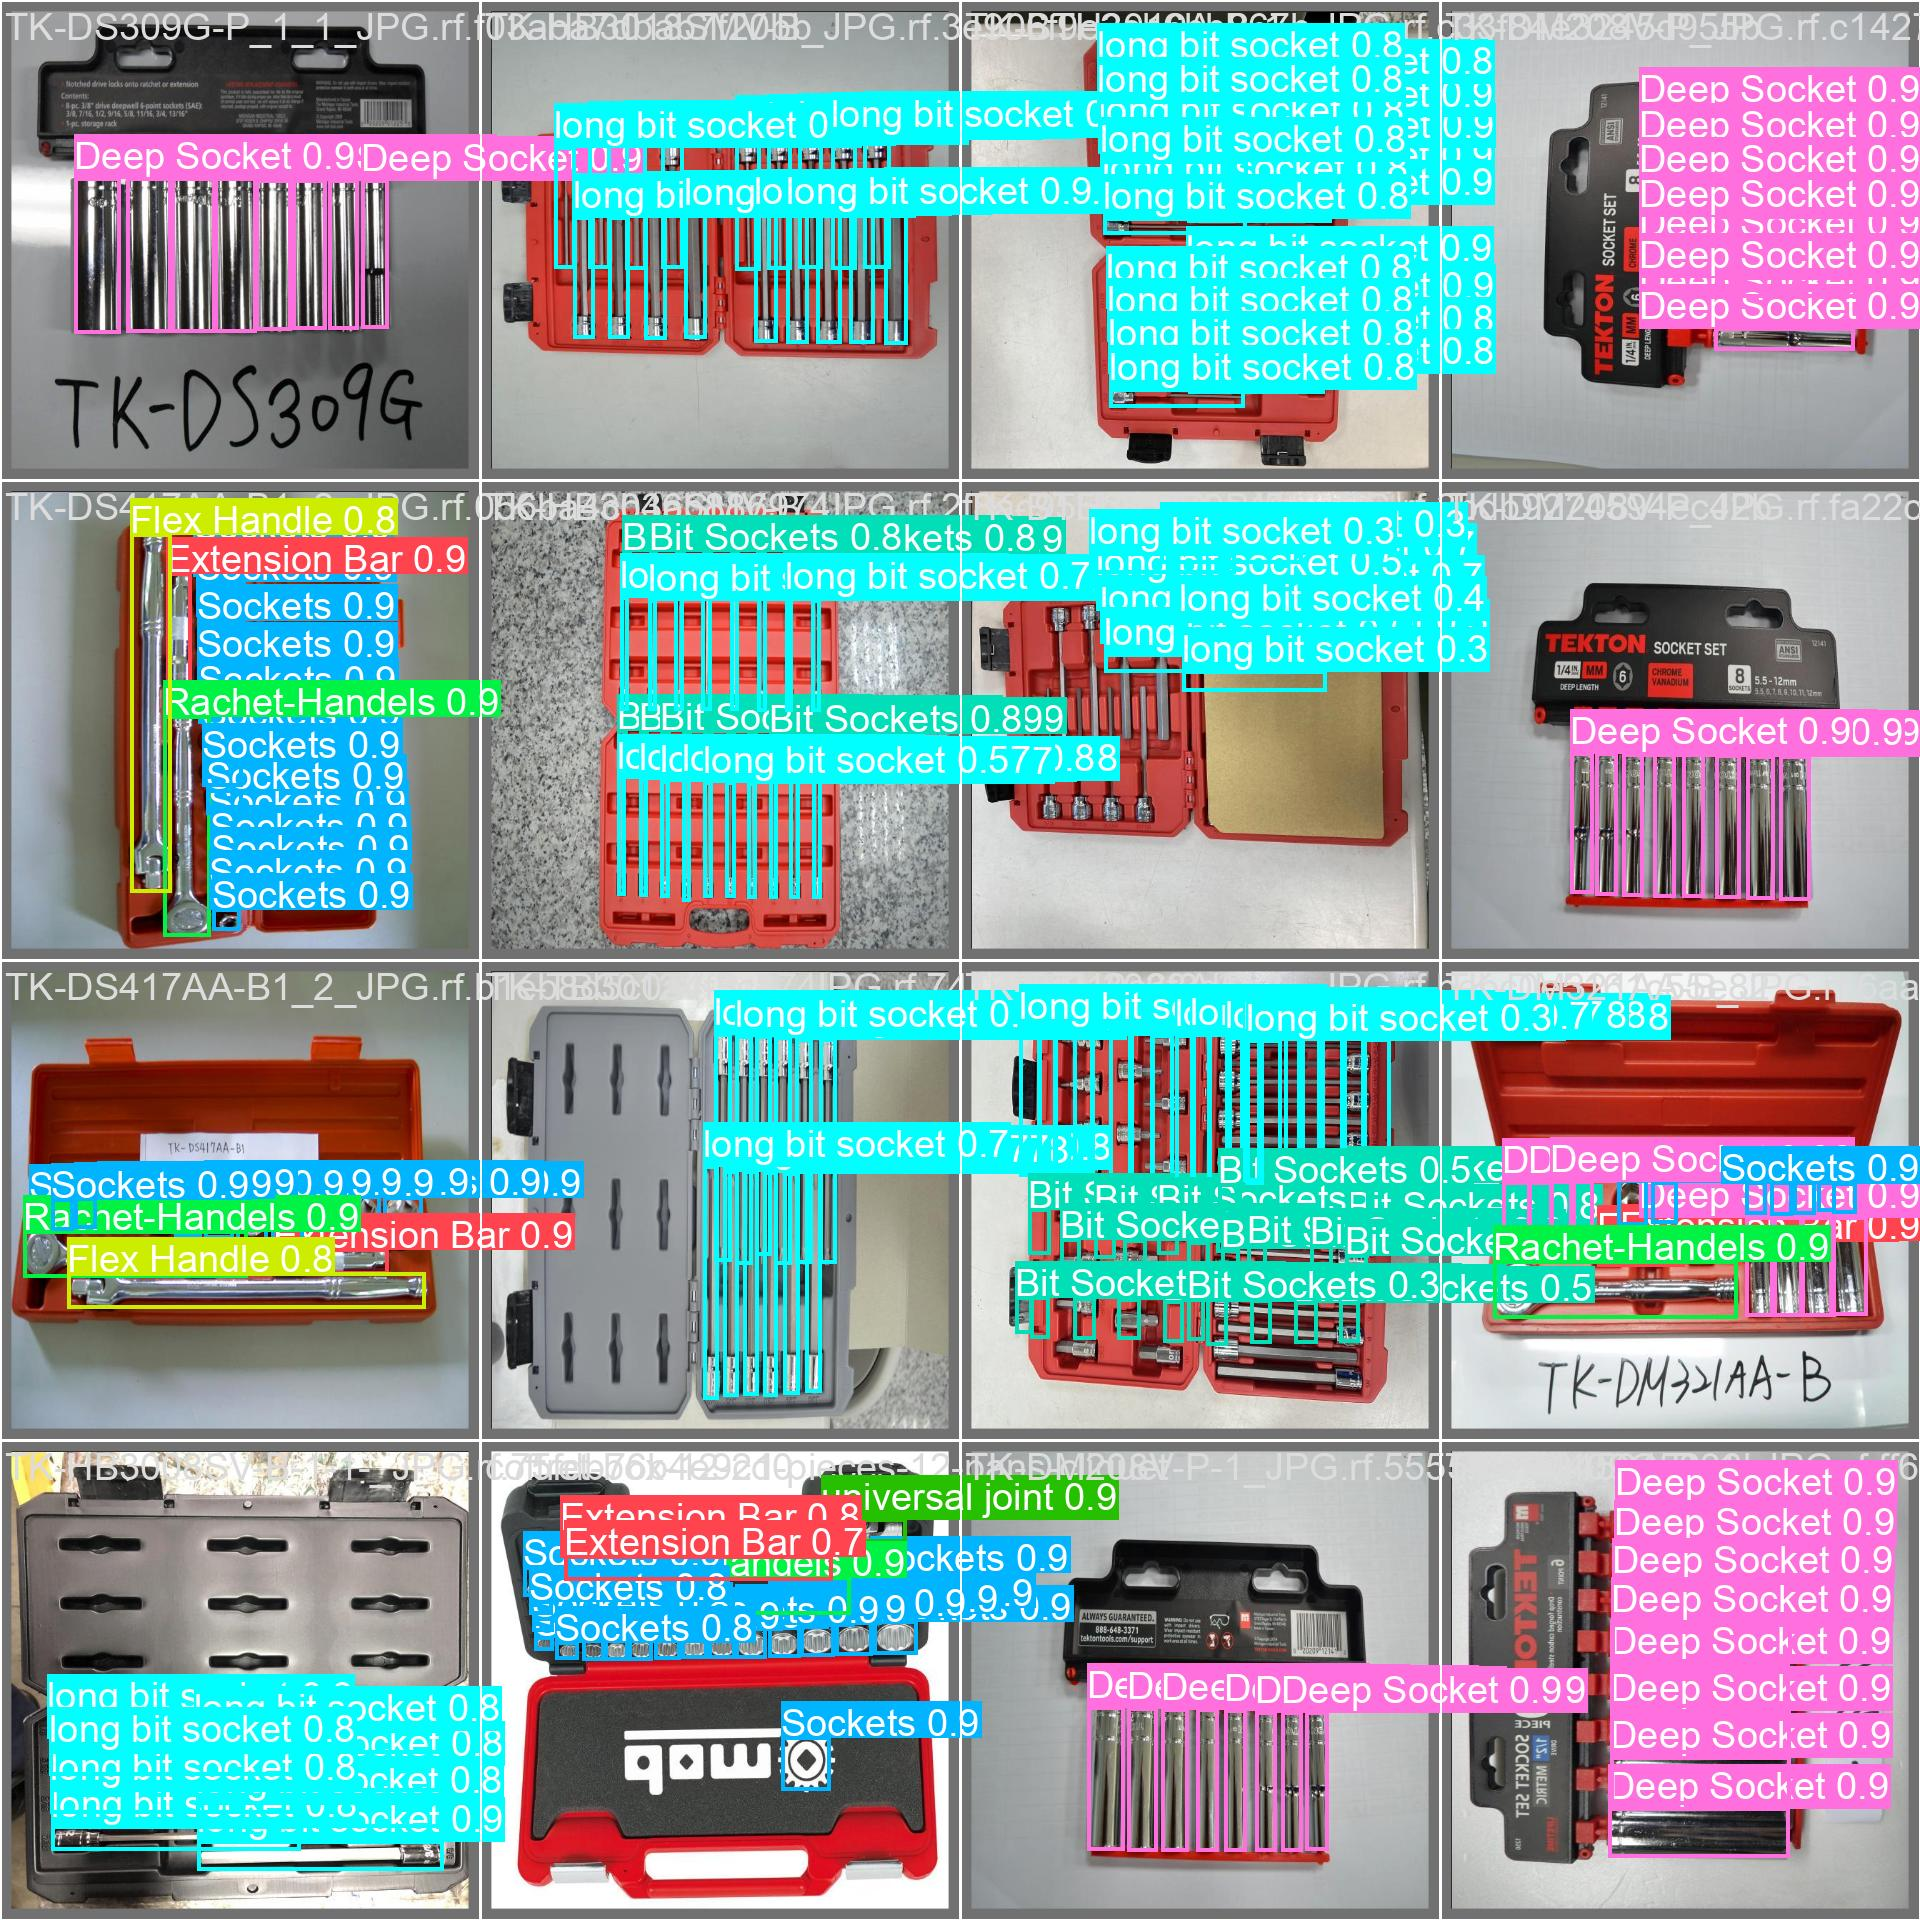

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

## Validate fine-tuned model

In [ ]:
!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
YOLO11s summary (fused): 238 layers, 9,418,218 parameters, 0 gradients, 21.3 GFLOPs
val: Scanning /content/datasets/YOLV5-Detection-3/valid/labels.cache... 284 images, 0 backgrounds, 0 corrupt: 100% 284/284 [00:00<?, ?it/s]
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 497, len(boxes) = 8369. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 18/18 [00:07<00:00,  2.29it/s]
                   all        284       8369      0.933      0.889      0.931      0.758
               Adaptor         34         48      0.856      0.854      0.892      0.743
             Allen Key          6          6      0.903          1      0.995      0.905
            Bit

## Inference with custom model

In [ ]:
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
YOLO11s summary (fused): 238 layers, 9,418,218 parameters, 0 gradients, 21.3 GFLOPs

image 1/141 /content/datasets/YOLV5-Detection-3/test/images/1-2-drive-flat-socket-spanners-500x500_webp.rf.334e032ed87e1e8545dd1c892b9ef7f9.jpg: 640x640 3 Extension Bars, 1 Rachet-Handels, 10 Socketss, 13.7ms
image 2/141 /content/datasets/YOLV5-Detection-3/test/images/144TMPB_v2_webp.rf.551f87b100aab01da75f7aa9377c4e32.jpg: 640x640 19 Deep Sockets, 2 Extension Bars, 1 Rachet-Handels, 20 Socketss, 1 universal joint, 11.5ms
image 3/141 /content/datasets/YOLV5-Detection-3/test/images/15-54_webp.rf.461486f4853a8b785ead26aa2c5ffa3e.jpg: 640x640 13 Extension Bars, 3 Rachet-Handelss, 95 Socketss, 2 universal joints, 10.5ms
image 4/141 /content/datasets/YOLV5-Detection-3/test/images/15-54_webp.rf.fac63d92770982ba22aa12f249765b1c.jpg: 640x640 16 Extension Bars, 2 Rachet-Handelss, 95 Socketss, 2 universal joints, 10.1m

**NOTE:** Let's take a look at few results.

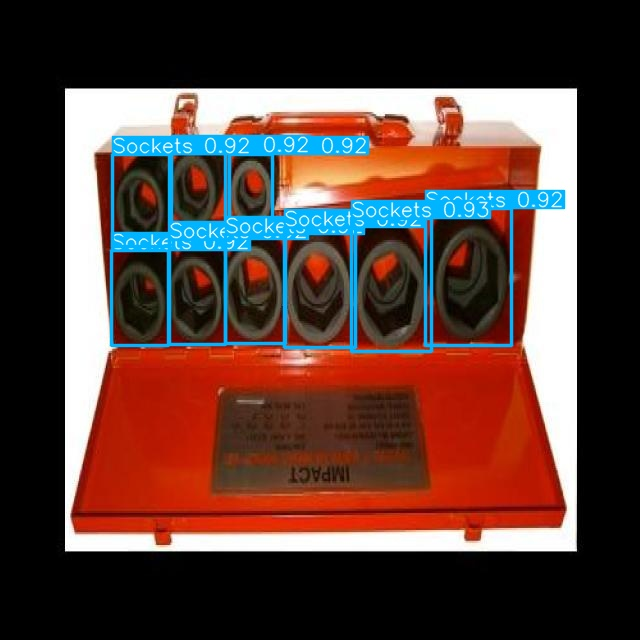

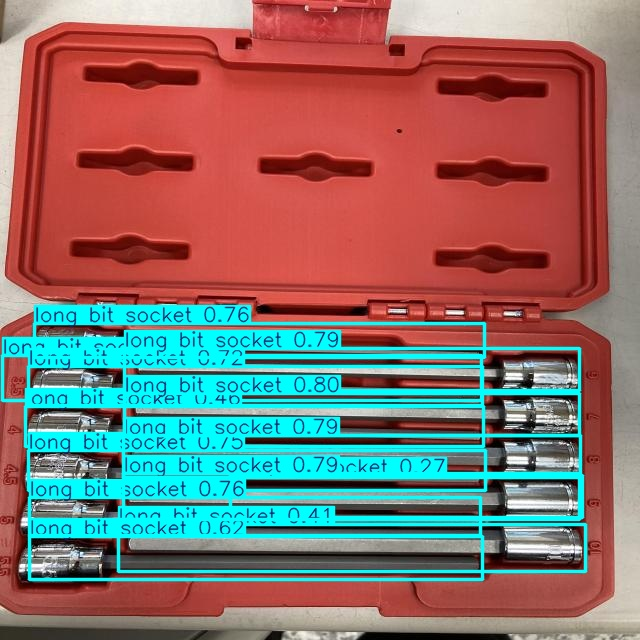

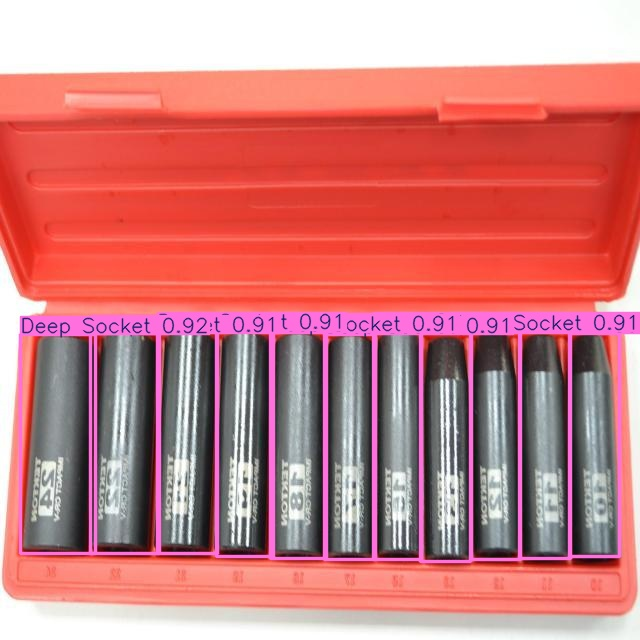

In [ ]:
import glob
import os
from IPython.display import Image as IPyImage, display

latest_folder = max(glob.glob(f'{HOME}/runs/detect/predict*/'), key=os.path.getmtime)
for img in glob.glob(f'{latest_folder}/*.jpg')[:3]:
    display(IPyImage(filename=img, width=600))
    print("\n")